<a href="https://colab.research.google.com/github/Diosito-apt/Data_Science_Pract/blob/main/Hackaton_3_Regresion_PrecioCarros_Grupo_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hackatón 3: Predicción del precio de automóviles 🚗

## Reto

En equipo, desarrollen un flujo reproducible de aprendizaje automático que estime el precio de un automóvil a partir de sus características. Comparen varios modelos de regresión, interpreten sus errores y defiendan cuál recomendarían para este conjunto de datos.

**Pregunta guía:** ¿qué características ayudan a estimar el precio y qué tan confiables son las predicciones del modelo?

**Reglas de trabajo:** separen los datos de entrenamiento y prueba antes de ajustar cualquier transformación; todo imputador, codificador y escalador debe aprenderse solo con los datos de entrenamiento. No interpreten una asociación como causalidad.


## Objetivos de aprendizaje

Al finalizar, podrán:

1. revisar y preparar un conjunto de datos tabular para regresión;
2. construir un preprocesamiento que maneje variables numéricas y categóricas;
3. comparar regresión lineal, regresión polinómica, Ridge y Lasso;
4. evaluar con RMSE, MAE, R² y MAPE, e interpretar las métricas en el contexto del problema;
5. comunicar una recomendación respaldada por resultados y limitaciones.


## Organización y entregables

Trabajen en equipos. Distribuyan responsabilidades (datos, modelado, evaluación y presentación), aunque todas las personas deben poder explicar el flujo completo.

Al finalizar, entreguen este notebook ejecutado y una síntesis de máximo 5 diapositivas o 3 minutos que incluya: problema, decisiones de preparación, tabla comparativa, interpretación de errores, modelo recomendado y limitaciones. Registren las decisiones importantes en las celdas de reflexión.


## VERSIÓN PYTHON 3.10.10

## 0. Preparación en Visual Studio Code
## Versión Python 3.10.10

In [4]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error,
    mean_absolute_percentage_error, r2_score,
)
from sklearn.model_selection import (
    train_test_split, KFold, GridSearchCV, cross_val_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures

pd.set_option('display.max_columns', 32)
print('Python:', sys.version.split()[0])
print('Directorio de trabajo:', Path.cwd())

Python: 3.13.18
Directorio de trabajo: /content


## 1. Conocer los datos

El archivo esperado es `Caso_Precio_Automovil_vf.csv` y usa `;` como separador. Si el archivo tiene otro nombre o ubicación, ajusten la ruta. Primero revisen las columnas y tipos; el nombre de la variable objetivo puede aparecer como `precio` o `precio_automovil`, así que confirmen el nombre real.


In [5]:
RUTA_CSV = Path('/content/Caso_Precio_Automovil_vf.csv')
if not RUTA_CSV.is_file():
    raise FileNotFoundError(
        f'No encuentro {RUTA_CSV.name} en {Path.cwd()}. '
        'Coloca el CSV junto al notebook y abre esa carpeta en VS Code, '
        'o cambia RUTA_CSV a una ruta absoluta.'
    )

df = pd.read_csv(RUTA_CSV, sep=';', na_values=['?', ''], skipinitialspace=True)
df.columns = df.columns.str.strip().str.lower()
print(f'Tamaño: {df.shape[0]} filas × {df.shape[1]} columnas')
display(df.head())
df.info()


Tamaño: 205 filas × 26 columnas


,id,riesgo,nombre_auto,tipo_combustible,aspiracion,numero_puertas,carroceria,traccion,ubicacion_motor,distancia_ejes,longitud_auto,ancho_auto,altura_auto,peso_auto,tipo_motor,numero_cilindros,dimension_motor,sistema_combustible,bore_ratio,cilindrada,compresion_ratio,hp,rpm,mpg_ciudad,mpg_carretera,precio_automovil
0,1,NaN,alfa-romero giulia,gas,std,dos,convertible,rwd,frente,88.6,168.8,64.1,48.8,2548,dohc,cuatro,130,mpfi,3.47,2.68,9.0,111.0,5000,21,27,13495.0
1,2,-1.0,toyota starlet,gas,std,cuatro,sedan,rwd,frente,104.5,187.8,66.5,54.1,3131,dohc,seis,171,mpfi,3.27,3.35,9.2,NaN,5200,20,24,15690.0
2,3,0.0,volkswagen rabbit custom,diesel,turbo,cuatro,sedan,fwd,frente,100.4,180.2,NaN,55.1,2579,ohc,cuatro,97,idi,3.01,3.40,23.0,68.0,4500,33,38,13845.0
3,4,3.0,dodge coronet custom (sw),gas,turbo,dos,hatchback,fwd,frente,95.9,173.2,66.3,50.2,2811,ohc,cuatro,156,mfi,3.60,3.90,7.0,145.0,5000,19,24,12964.0
4,5,0.0,toyota corona,gas,std,cuatro,sedan,fwd,frente,95.7,166.3,64.4,53.0,2094,ohc,cuatro,98,2bbl,3.19,3.03,9.0,70.0,4800,38,47,7738.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   205 non-null    int64  
 1   riesgo               183 non-null    float64
 2   nombre_auto          205 non-null    object 
 3   tipo_combustible     205 non-null    object 
 4   aspiracion           205 non-null    object 
 5   numero_puertas       192 non-null    object 
 6   carroceria           205 non-null    object 
 7   traccion             205 non-null    object 
 8   ubicacion_motor      205 non-null    object 
 9   distancia_ejes       199 non-null    float64
 10  longitud_auto        203 non-null    float64
 11  ancho_auto           194 non-null    float64
 12  altura_auto          205 non-null    float64
 13  peso_auto            205 non-null    int64  
 14  tipo_motor           205 non-null    object 
 15  numero_cilindros     205 non-null    obj

### Diccionario de variables

| Variable | Descripción |
|---|---|
| `riesgo` | Indicador de riesgo de seguro |
| `Nombre_auto` | Marca y versión del vehículo |
| `tipo_combustible` | Tipo de combustible |
| `aspiracion` | Tipo de aspiración |
| `numero_puertas` | Número de puertas |
| `carroceria` | Tipo de carrocería |
| `traccion` | Tipo de tracción |
| `ubicacion_motor` | Ubicación del motor |
| `distancia_ejes`, `longitud_auto`, `ancho_auto`, `altura_auto` | Dimensiones del automóvil |
| `peso_auto` | Peso en vacío |
| `tipo_motor`, `numero_cilindros` | Tipo y número de cilindros |
| `dimension_motor`, `cilindrada`, `bore_ratio`, `compresion_ratio` | Características del motor |
| `sistema_combustible` | Sistema de inyección |
| `hp`, `rpm` | Potencia y revoluciones por minuto |
| `mpg_ciudad`, `mpg_carretera` | Rendimiento en ciudad y carretera |
| `precio` o `precio_automovil` | **Variable objetivo:** precio del automóvil |

Los nombres pueden variar ligeramente en el archivo. Usen `df.columns` para confirmar. La columna `id`, si existe, es un identificador y no debe usarse como predictor.


## Análisis funcional del perfil de datos

En esta parte del notebook realizamos un diagnóstico de la información para entender con qué datos contamos y qué tan preparados están para construir nuestros modelos de regresión.

Revisamos la estructura del dataset, los tipos de variables, valores nulos, duplicados y la distribución de precios.

In [6]:
# Inspeccionen nombres, valores faltantes y cardinalidad de las variables.
perfil = pd.DataFrame({
    'Tipo': df.dtypes.astype(str),
    'Nulos': df.isna().sum(),
    '% nulos': (df.isna().mean() * 100).round(2),
    'Valores únicos': df.nunique(dropna=True),
}).sort_values('% nulos', ascending=False)
print('Duplicados exactos:', df.duplicated().sum())
print('IDs duplicados:', df['id'].duplicated().sum())
print('Nombres distintos:', df['nombre_auto'].nunique())
display(perfil)
display(df['precio_automovil'].describe(percentiles=[.10, .25, .50, .75, .90, .95]).to_frame())


Duplicados exactos: 0
IDs duplicados: 0
Nombres distintos: 147


,Tipo,Nulos,% nulos,Valores únicos
riesgo,float64,22,10.73,6
hp,float64,19,9.27,54
numero_puertas,object,13,6.34,2
ancho_auto,float64,11,5.37,44
distancia_ejes,float64,6,2.93,51
longitud_auto,float64,2,0.98,75
aspiracion,object,0,0.00,2
id,int64,0,0.00,205
tipo_combustible,object,0,0.00,2
nombre_auto,object,0,0.00,147


,precio_automovil
count,205.000000
mean,13276.710571
std,7988.852332
min,5118.000000
10%,6657.000000
25%,7788.000000
50%,10295.000000
75%,16503.000000
90%,22563.000000
95%,32472.400000


# Evidencia y resultados del perfilamiento

Como resultado, identificamos que no tenemos registros ni IDs duplicados, aunque sí existen algunas variables con información faltante que debemos tratar antes del entrenamiento:
- `riesgo` tiene 22 faltantes; `hp`, 19; `numero_puertas`, 13; `ancho_auto`, 11; `distancia_ejes`, 6; y `longitud_auto`, 2.
- No se encontraron duplicados exactos. `id` identifica una fila, no una característica predictiva válida.
- `nombre_auto` contiene muchos nombres distintos (147 de 205), lo que aumenta la dimensionalidad si lo codificamos sin tratamiento.
- La distribución del precio es asimétrica: mediana cercana a 10,295 y máximo 45,400.

Con estos hallazgos podemos definir los ajustes necesarios para preparar los datos, seleccionar las variables más útiles y reducir posibles errores durante el entrenamiento.

En conclusión, esta revisión nos permite establecer una línea base de calidad de datos y tomar decisiones sustentadas antes de construir y comparar los modelos predictivos.

**Precaución:** las métricas de correlación que dibujamos son descriptivas; no prueban que una característica cause un precio mayor o menor.

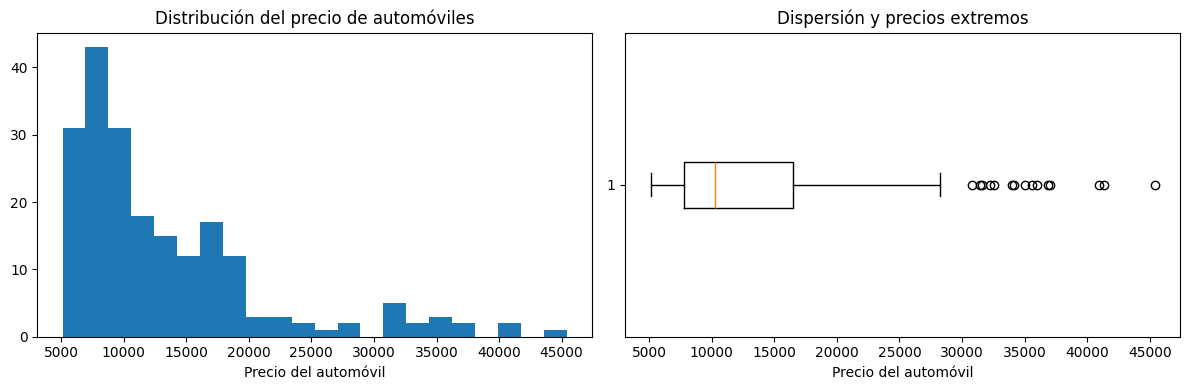

Correlaciones descriptivas con el precio (por magnitud):


,Correlación
dimension_motor,0.874
peso_auto,0.835
hp,0.814
ancho_auto,0.765
mpg_carretera,-0.698
mpg_ciudad,-0.686
longitud_auto,0.683
distancia_ejes,0.635
bore_ratio,0.553
riesgo,-0.153


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df['precio_automovil'].dropna(), bins=22)
axes[0].set_title('Distribución del precio de automóviles')
axes[0].set_xlabel('Precio del automóvil')
axes[1].boxplot(df['precio_automovil'].dropna(), vert=False)
axes[1].set_title('Dispersión y precios extremos')
axes[1].set_xlabel('Precio del automóvil')
plt.tight_layout()
plt.show()

corr_precio = (
    df.select_dtypes(include='number').corr(numeric_only=True)
      ['precio_automovil'].drop('precio_automovil').drop('id', errors='ignore')
      .sort_values(key=lambda s: s.abs(), ascending=False)
)
print('Correlaciones descriptivas con el precio (por magnitud):')
display(corr_precio.to_frame('Correlación').head(10).round(3))

## 2. Preparación de datos

Reemplacen marcadores de ausencia (`?`) por valores faltantes. Identifiquen el objetivo, eliminen filas sin precio conocido y excluyan identificadores. No imputen ni escalen manualmente antes de separar entrenamiento y prueba: esas operaciones se integrarán en un `Pipeline`.

**Acciones:**

- Normalizar espacios, signos `?` y valores vacíos.
- Convertir columnas numéricas conocidas usando `pd.to_numeric(errors='coerce')`.
- Eliminar únicamente filas con **Y** desconocida.
- Excluir `id` por ser identificador.
- **No usar el nombre completo del automóvil** como predictor principal; extraemos la **marca** como una categoría menos específica; la extracción es por cada fila.
- No imputamos todavía: las medianas y categorías frecuentes se calcularán *dentro del pipeline* usando solo entrenamiento.

La marca puede aportar información comercial, pero hay pocos ejemplos por algunas marcas. Más adelante contrastamos su efecto sobre la validación.

In [8]:
# Normalizar marcadores de datos faltantes y espacios en nombres de columnas.
# Detectar el nombre de objetivo esperado; si no aparece, indiquen el nombre correcto.
# Excluir identificadores, cuando existan, y quitar filas sin etiqueta.
df_limpio = df.copy()

for columna in df_limpio.select_dtypes(include=['object']).columns:
    df_limpio[columna] = (
        df_limpio[columna].str.strip().replace({'?': np.nan, '': np.nan})
    )

numericas_esperadas = [
    'riesgo', 'distancia_ejes', 'longitud_auto', 'ancho_auto',
    'altura_auto', 'peso_auto', 'dimension_motor', 'bore_ratio',
    'cilindrada', 'compresion_ratio', 'hp', 'rpm',
    'mpg_ciudad', 'mpg_carretera',
]
OBJETIVO = 'precio_automovil'
for c in numericas_esperadas + [OBJETIVO]:
    df_limpio[c] = pd.to_numeric(df_limpio[c], errors='coerce')

filas_sin_precio = df_limpio[OBJETIVO].isna().sum()
df_limpio = df_limpio.dropna(subset=[OBJETIVO]).copy()
assert (df_limpio[OBJETIVO] > 0).all(), 'Los precios deben ser positivos para calcular MAPE.'

df_limpio['marca'] = df_limpio['nombre_auto'].str.split().str[0].str.lower()

X = df_limpio.drop(columns=['id', 'nombre_auto', OBJETIVO])
y = df_limpio[OBJETIVO]

print('Filas sin precio excluidas:', filas_sin_precio)
print('Características:', X.shape[1], '| Numéricas:', len(X.select_dtypes(include='number').columns),
      '| Categóricas:', len(X.select_dtypes(exclude='number').columns))
print('Marcas distintas:', df_limpio['marca'].nunique())
display(X.head(3))

Filas sin precio excluidas: 0
Características: 24 | Numéricas: 14 | Categóricas: 10
Marcas distintas: 27


,riesgo,tipo_combustible,aspiracion,numero_puertas,carroceria,traccion,ubicacion_motor,distancia_ejes,longitud_auto,ancho_auto,altura_auto,peso_auto,tipo_motor,numero_cilindros,dimension_motor,sistema_combustible,bore_ratio,cilindrada,compresion_ratio,hp,rpm,mpg_ciudad,mpg_carretera,marca
0,NaN,gas,std,dos,convertible,rwd,frente,88.6,168.8,64.1,48.8,2548,dohc,cuatro,130,mpfi,3.47,2.68,9.0,111.0,5000,21,27,alfa-romero
1,-1.0,gas,std,cuatro,sedan,rwd,frente,104.5,187.8,66.5,54.1,3131,dohc,seis,171,mpfi,3.27,3.35,9.2,NaN,5200,20,24,toyota
2,0.0,diesel,turbo,cuatro,sedan,fwd,frente,100.4,180.2,NaN,55.1,2579,ohc,cuatro,97,idi,3.01,3.40,23.0,68.0,4500,33,38,volkswagen


### Reflexión breve: decisiones de calidad

**Columnas descartadas:** `id` (identificador) y `nombre_auto` (alta cardinalidad).

**Variable derivada:** `marca`, obtenida del primer término del nombre, para recuperar una parte de la información comercial sin crear una categoría por cada versión.

**Variables con más faltantes:** `riesgo`, `hp` y `numero_puertas`. No se reemplazan manualmente antes de separar conjuntos; la imputación queda dentro del pipeline.

**Riesgos adicionales:** algunas marcas tienen pocos ejemplos, la nomenclatura puede ser inconsistente y `riesgo` podría tratarse como categoría ordinal en un experimento alternativo. Los valores de precio deben interpretarse en el contexto histórico del dataset, no como cotizaciones actuales.

## 3. Separación de entrenamiento y prueba 80/20

Reservaremos el 20 % para comparar el desempeño en datos no usados durante el ajuste. Como comparar varias alternativas puede influir en la elección del modelo, interpreten esta comparación como una evaluación interna; para una selección más rigurosa, usen validación cruzada sobre entrenamiento (extensión opcional). Las transformaciones se ajustan dentro de los pipelines usando únicamente los datos de entrenamiento.

Reservamos **41 automóviles para prueba** y utilizamos **164 para entrenamiento**, con semilla 42. La validación cruzada se hará exclusivamente dentro de los 164 vehículos de entrenamiento.

No debemos mirar el conjunto de prueba para ajustar parámetros, elegir el modelo o decidir qué transformación funciona mejor.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
assert X_train.index.intersection(X_test.index).empty
print(f'Entrenamiento: {len(X_train)} automóviles')
print(f'Prueba: {len(X_test)} automóviles')
print('Mediana del precio en entrenamiento:', round(y_train.median(), 2))
print('Mediana del precio en prueba:', round(y_test.median(), 2))


Entrenamiento: 164 automóviles
Prueba: 41 automóviles
Mediana del precio en entrenamiento: 10270.0
Mediana del precio en prueba: 10345.0


## 4. Preprocesamiento sin fuga de información, con `Pipeline` y `ColumnTransformer`

El pipeline imputará la mediana en columnas numéricas, imputará la categoría más frecuente en columnas categóricas, estandarizará las numéricas y aplicará one-hot encoding a las categóricas. El `ColumnTransformer` detecta los tipos a partir de `X_train`; las transformaciones se ajustan al llamar a `fit` sobre cada pipeline.

**-------------------------------------------------------------------------------------------------------------------------------**

**Numéricas:** imputación por mediana + `StandardScaler`.

**Categóricas:** imputación por la categoría más frecuente + `OneHotEncoder(handle_unknown='ignore')`.

El modelo polinómico expande a grado 2 **solo cuatro variables numéricas seleccionadas por su significado técnico** (`dimension_motor`, `peso_auto`, `hp`, `mpg_ciudad`). Expandir todas las columnas, incluida la marca, produciría demasiados coeficientes para una muestra de 205 filas.

Nota: `riesgo` se utiliza aquí como puntuación numérica/ordinal; la decisión se podría contrastar en otra validación.


In [10]:
cols_num = X_train.select_dtypes(include='number').columns.tolist()
cols_cat = X_train.select_dtypes(exclude='number').columns.tolist()

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
])

preprocess_normal = ColumnTransformer([
    ('num', num_pipeline, cols_num),
    ('cat', cat_pipeline, cols_cat),
])

cols_poly = ['dimension_motor', 'peso_auto', 'hp', 'mpg_ciudad']
cols_num_restantes = [c for c in cols_num if c not in cols_poly]

poly_num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('scaler_poly', StandardScaler()),
])
preprocess_polinomico = ColumnTransformer([
    ('poly_num', poly_num_pipeline, cols_poly),
    ('num', num_pipeline, cols_num_restantes),
    ('cat', cat_pipeline, cols_cat),
])
print('Variables numéricas:', cols_num)
print('Variables categóricas:', cols_cat)
print('Variables con expansión polinómica:', cols_poly)

Variables numéricas: ['riesgo', 'distancia_ejes', 'longitud_auto', 'ancho_auto', 'altura_auto', 'peso_auto', 'dimension_motor', 'bore_ratio', 'cilindrada', 'compresion_ratio', 'hp', 'rpm', 'mpg_ciudad', 'mpg_carretera']
Variables categóricas: ['tipo_combustible', 'aspiracion', 'numero_puertas', 'carroceria', 'traccion', 'ubicacion_motor', 'tipo_motor', 'numero_cilindros', 'sistema_combustible', 'marca']
Variables con expansión polinómica: ['dimension_motor', 'peso_auto', 'hp', 'mpg_ciudad']


## 5. Entrenamiento y comparación de modelos

Entrenen cuatro alternativas: regresión lineal como referencia, regresión polinómica de grado 2, Ridge y Lasso. La expansión polinómica se aplica solo a las variables numéricas para controlar el crecimiento de características. Ridge y Lasso ayudan a regularizar el modelo; en la extensión pueden explorar distintos valores de `alpha`.


In [11]:
modelos = {
    'Lineal': (
        Pipeline([('prep', preprocess_normal), ('model', LinearRegression())]),
        {},
    ),
    'Polinomica_grado_2': (
        Pipeline([('prep', preprocess_polinomico), ('model', LinearRegression())]),
        {},
    ),
    'Ridge': (
        Pipeline([('prep', preprocess_normal), ('model', Ridge())]),
        {'model__alpha': [0.1, 1, 10, 100, 1000]},
    ),
    'Lasso': (
        Pipeline([('prep', preprocess_normal),
                  ('model', Lasso(max_iter=30000, tol=0.001))]),
        {'model__alpha': [1, 10, 50, 100, 500]},
    ),
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)
busquedas = {}
filas_metricas = []

for nombre, (pipeline, grid) in modelos.items():
    busqueda = GridSearchCV(
        estimator=pipeline,
        param_grid=grid,
        scoring='neg_root_mean_squared_error',
        cv=cv,
        n_jobs=1,
        refit=True,
        error_score='raise',
    )
    busqueda.fit(X_train, y_train)
    busquedas[nombre] = busqueda

    pred_train = busqueda.predict(X_train)
    pred_test = busqueda.predict(X_test)
    idx = busqueda.best_index_

    filas_metricas.append({
        'Modelo': nombre,
        'CV_RMSE': -busqueda.best_score_,
        'CV_DesvStd': busqueda.cv_results_['std_test_score'][idx],
        'RMSE_Train': np.sqrt(mean_squared_error(y_train, pred_train)),
        'RMSE_Test': np.sqrt(mean_squared_error(y_test, pred_test)),
        'MAE_Test': mean_absolute_error(y_test, pred_test),
        'R2_Test': r2_score(y_test, pred_test),
        'MAPE_Test_%': 100 * mean_absolute_percentage_error(y_test, pred_test),
        'Mejor_alpha': busqueda.best_params_.get('model__alpha', 'No aplica'),
    })

resultado = pd.DataFrame(filas_metricas).sort_values('CV_RMSE').reset_index(drop=True)
display(resultado.round(3))


,Modelo,CV_RMSE,CV_DesvStd,RMSE_Train,RMSE_Test,MAE_Test,R2_Test,MAPE_Test_%,Mejor_alpha
0,Lasso,2215.490,347.866,1430.262,2553.406,1577.553,0.917,11.650,10
1,Ridge,2241.376,237.056,1452.279,2567.053,1559.102,0.916,11.175,1
2,Polinomica_grado_2,2859.069,793.052,1073.852,2754.513,1799.798,0.904,14.058,No aplica
3,Lineal,2879.131,731.296,1291.099,2556.669,1761.598,0.917,14.333,No aplica


### ¿Por qué usamos CV_RMSE y no RMSE_Test para elegir?

La prueba debe simular información que nunca utilizamos para tomar decisiones. Si probamos decenas de alternativas y elegimos la que obtuvo mejor resultado en prueba, el conjunto de prueba se convierte de hecho en un conjunto de validación.

**Regla:** seleccionar por `CV_RMSE` de entrenamiento; después consultar `RMSE_Test`, `MAE_Test`, `R2_Test` y `MAPE_Test_%` para estimar cómo funciona esa elección fuera de entrenamiento.

Los valores de **CV** pueden variar entre particiones: comparar las desviaciones típicas ayuda a detectar que dos modelos aparentemente diferentes podrían tener desempeños muy cercanos.

## 6. Evaluación: contra un modelo de referencia (*baseline*)

Calculen las métricas en el conjunto de prueba. **RMSE y MAE se expresan en las mismas unidades que el precio**; RMSE penaliza más los errores grandes. R² compara el modelo con una predicción basada en la media, pero no representa un porcentaje de predicciones correctas. MAPE se reporta como porcentaje y puede ser inestable si hay precios iguales o cercanos a cero; verifiquen ese supuesto.

**------------------------------------------------------------------------------------------------------------------------------------------------**

Antes de aceptar cualquier algoritmo, lo comparamos contra una regla trivial: **predecir siempre la mediana del precio de entrenamiento**. Si un modelo sofisticado no consigue mejorarla, no estaría demostrando valor predictivo.


In [12]:
baseline = DummyRegressor(strategy='median')
baseline.fit(X_train, y_train)
pred_baseline = baseline.predict(X_test)

tabla_baseline = pd.DataFrame([{
    'Modelo': 'Baseline - mediana',
    'MAE_Test': mean_absolute_error(y_test, pred_baseline),
    'RMSE_Test': np.sqrt(mean_squared_error(y_test, pred_baseline)),
    'R2_Test': r2_score(y_test, pred_baseline),
    'MAPE_Test_%': 100 * mean_absolute_percentage_error(y_test, pred_baseline),
}])
display(tabla_baseline.round(2))

# El candidato ganador se define por CV, nunca por los resultados de prueba.
modelo_elegido = resultado.loc[0, 'Modelo']
mejor_busqueda = busquedas[modelo_elegido]
mejor_modelo = mejor_busqueda.best_estimator_
y_pred = mejor_modelo.predict(X_test)
print('Modelo candidato por validación cruzada:', modelo_elegido)
print('Parámetros elegidos por CV:', mejor_busqueda.best_params_)


,Modelo,MAE_Test,RMSE_Test,R2_Test,MAPE_Test_%
0,Baseline - mediana,6263.55,9590.47,-0.17,39.92


Modelo candidato por validación cruzada: Lasso
Parámetros elegidos por CV: {'model__alpha': 10}


## 6.1. Analizar errores: vehículos económicos frente a caros

Elijan el modelo con mejor RMSE y examinen sus predicciones. ¿Comete errores especialmente grandes en automóviles caros o baratos? ¿Hay señales de sobreajuste? Comparen también MAE y R²; no seleccionen un modelo basándose en una sola cifra sin explicar el criterio.

**----------------------------------------------------------------------------------------------------------------------------------**
La pregunta funcional no es únicamente «¿qué modelo tiene menor RMSE?», sino **«¿en qué tipos de automóviles se equivoca más?»**.

Mediremos el MAE de prueba en tres segmentos de precio definidos para este análisis descriptivo: hasta 10,000; entre 10,000 y 20,000; y más de 20,000. Los segmentos son ilustrativos, no categorías comerciales oficiales.


In [13]:
errores = pd.DataFrame({
    'id': df_limpio.loc[y_test.index, 'id'].to_numpy(),
    'Precio_real': y_test.to_numpy(),
    'Precio_predicho': y_pred,
})
errores['Residuo'] = errores['Precio_real'] - errores['Precio_predicho']
errores['Error_absoluto'] = errores['Residuo'].abs()
errores['Error_porcentual'] = 100 * errores['Error_absoluto'] / errores['Precio_real']
errores['Segmento'] = pd.cut(
    errores['Precio_real'], bins=[0, 10000, 20000, np.inf],
    labels=['Económico ≤ 10 mil', 'Medio 10–20 mil', 'Alto > 20 mil'],
    include_lowest=True,
)

segmentos = errores.groupby('Segmento', observed=False).agg(
    Vehiculos=('Precio_real', 'size'),
    MAE=('Error_absoluto', 'mean'),
    Error_porcentual_medio=('Error_porcentual', 'mean'),
)
print('Error por segmento de precio:')
display(segmentos.round(2))
print('Mayores errores individuales:')
display(errores.nlargest(8, 'Error_absoluto').round(2))

Error por segmento de precio:


,Vehiculos,MAE,Error_porcentual_medio
Segmento,,,
Económico ≤ 10 mil,20,963.20,12.86
Medio 10–20 mil,14,1579.28,10.93
Alto > 20 mil,7,3329.40,9.65


Mayores errores individuales:


,id,Precio_real,Precio_predicho,Residuo,Error_absoluto,Error_porcentual,Segmento
29,195,41315.0,29424.31,11890.69,11890.69,28.78,Alto > 20 mil
21,102,35550.0,30189.85,5360.15,5360.15,15.08,Alto > 20 mil
19,144,13200.0,17582.23,-4382.23,4382.23,33.20,Medio 10–20 mil
20,61,25552.0,29010.92,-3458.92,3458.92,13.54,Alto > 20 mil
40,147,18150.0,14741.61,3408.39,3408.39,18.78,Medio 10–20 mil
1,10,12945.0,10169.89,2775.11,2775.11,21.44,Medio 10–20 mil
18,87,14399.0,16734.47,-2335.47,2335.47,16.22,Medio 10–20 mil
4,69,6575.0,8769.03,-2194.03,2194.03,33.37,Económico ≤ 10 mil


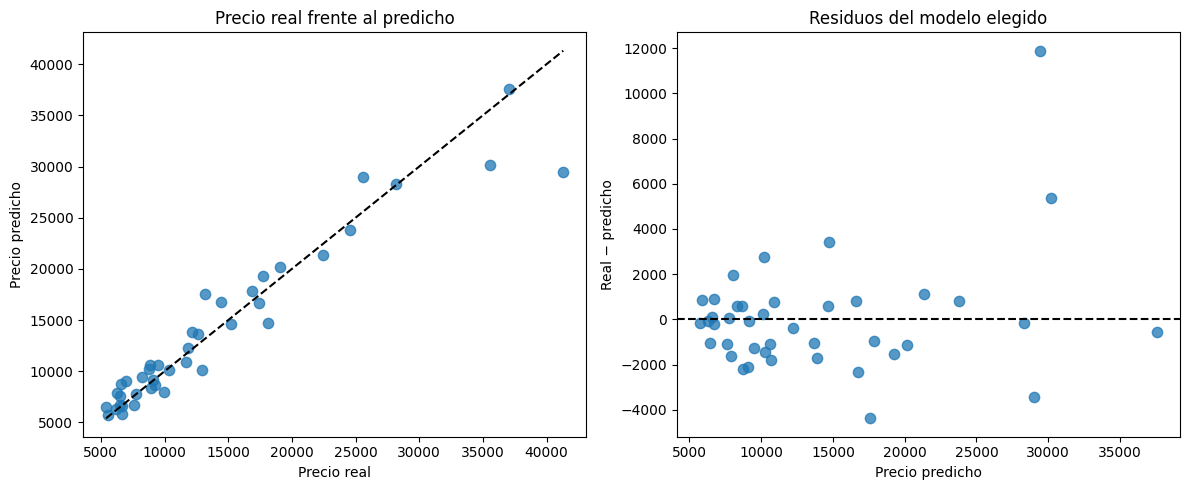

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(errores['Precio_real'], errores['Precio_predicho'], s=55, alpha=0.75)
minimo = min(errores['Precio_real'].min(), errores['Precio_predicho'].min())
maximo = max(errores['Precio_real'].max(), errores['Precio_predicho'].max())
axes[0].plot([minimo, maximo], [minimo, maximo], '--', color='black', label='Predicción perfecta')
axes[0].set_title('Precio real frente al predicho')
axes[0].set_xlabel('Precio real')
axes[0].set_ylabel('Precio predicho')

axes[1].scatter(errores['Precio_predicho'], errores['Residuo'], s=55, alpha=0.75)
axes[1].axhline(0, linestyle='--', color='black')
axes[1].set_title('Residuos del modelo elegido')
axes[1].set_xlabel('Precio predicho')
axes[1].set_ylabel('Real − predicho')
plt.tight_layout()
plt.show()

### ¿Cómo interpretar los gráficos?

- **Precio real vs. predicho:** cuanto más próximos estén los puntos a la línea diagonal, menor será el error.
- **Residuos:** valores por encima de cero significan que el modelo **subestimó** el precio; por debajo, que **lo sobreestimó**.
- **Errores en vehículos caros:** si son mayores, el modelo puede necesitar más ejemplos de ese segmento, información comercial adicional o un enfoque diferente.

Con solo 41 automóviles de prueba, los análisis por segmento son orientativos y tienen mayor incertidumbre que una evaluación con una muestra grande.

### Reflexión sobre resultados

Respondan con evidencia de la tabla y del análisis de errores:

1. ¿Qué modelo recomendarían y qué métrica fue decisiva?
Después de comparar los cuatro modelos, nos quedamos con **Lasso**, porque fue el que obtuvo el menor RMSE en validación cruzada (2,215 dólares) y un RMSE de 2,553 dólares en prueba.

También revisamos el MAE y R² para no quedarnos con una sola métrica, Ridge tuvo un MAE un poco menor, pero las diferencias fueron pequeñas; por eso consideramos que Lasso es una buena alternativa para nuestro ejercicio.

2. ¿Qué tan grande es el error típico en dólares según MAE?
Con Lasso obtuvimos un MAE de 1,578 dólares, en términos sencillos, significa que nuestras predicciones se equivocan, en promedio, por ese monto respecto al precio real del automóvil.

Es un resultado interesante, aunque el impacto de equivocarnos por 1,578 dólares no es el mismo para un automóvil económico que para uno de alta gama.

3. ¿Qué indica la diferencia entre RMSE y MAE sobre errores extremos?
Vemos que el RMSE (2,553 dólares) es bastante mayor que el MAE (1,578 dólares), esto nos da una señal de que tenemos algunas predicciones con errores más grandes que el promedio.

Al revisar los resultados, encontramos que nos equivocamos más en dólares, con los automóviles caros; en este grupo, el MAE llega a 3,329 dólares, mientras que en los económicos es de 963 dólares.

Esto es importante porque, aunque el modelo tenga buenos resultados generales, todavía hay casos donde la diferencia entre el precio estimado y el real es considerable.

4. ¿Qué limitación del conjunto de datos podría afectar el uso del modelo en otros automóviles o mercados?
Una limitación importante es que solo contamos con 205 automóviles, por lo que no necesariamente tenemos suficiente variedad para representar todo el mercado.

Además, algunas marcas tienen muy pocos registros y nos falta información que podría influir en el precio, como el año, kilometraje, estado del vehículo y condiciones del mercado.

Por eso, los resultados nos sirven para este ejercicio, pero necesitaríamos más información para comprobar qué tan bien funcionaría el modelo con otros automóviles.


**Respuesta del equipo:**
Conseguimos buenos resultados con los modelos de regresión y encontramos que **Lasso** es nuestra mejor alternativa según el RMSE de validación cruzada.

Sin embargo, también vimos que el modelo se equivoca más en algunos automóviles de mayor precio, esto nos deja claro que no basta con obtener buenas métricas generales, sino que también debemos revisar en qué casos estamos fallando.

Como siguiente paso, buscaríamos ampliar el dataset y mejorar la información disponible para conseguir predicciones más confiables antes de utilizar el modelo en un escenario real.


## 7. Extensión opcional: mejorar la selección

Si terminan antes, prueben varios valores de `alpha` para Ridge y Lasso mediante validación cruzada dentro del conjunto de entrenamiento. No ajusten hiperparámetros usando el conjunto de prueba. Como segundo experimento, comparen el desempeño con y sin `Nombre_auto` y discutan si la mejora podría reflejar memorización de marcas/modelos.

**Experimento realizado y resultado:**

> Documenten aquí el cambio, el resultado y su interpretación.


**Interpretar características sin confundir correlación con causalidad**

En un modelo lineal regularizado, el signo de un coeficiente sugiere dirección de una asociación **manteniendo las otras variables constantes**; no demuestra que modificar esa variable cause un cambio en el precio.

**Precaución:** los predictores numéricos fueron estandarizados y los categóricos codificados en indicadores. Por eso, las magnitudes absolutas de todos los coeficientes **no son directamente comparables** sin tener en cuenta sus unidades y codificación.


In [15]:
if modelo_elegido != 'Polinomica_grado_2':
    nombres = mejor_modelo.named_steps['prep'].get_feature_names_out()
    betas = mejor_modelo.named_steps['model'].coef_
    coeficientes = pd.DataFrame({
        'Característica transformada': nombres,
        'Coeficiente': betas,
        '|Coeficiente|': np.abs(betas),
    }).sort_values('|Coeficiente|', ascending=False)
    print('Coeficientes de mayor magnitud (descriptivos, no causales):')
    display(coeficientes.head(12).round(2))
else:
    print('La expansión polinómica introduce interacciones: interpretaremos el modelo principalmente mediante errores y curvas parciales.')

Coeficientes de mayor magnitud (descriptivos, no causales):


,Característica transformada,Coeficiente,|Coeficiente|
28,cat__ubicacion_motor_frente,-12997.64,12997.64
53,cat__marca_bmw,6482.33,6482.33
54,cat__marca_buick,4722.00,4722.00
35,cat__tipo_motor_rotor,3675.77,3675.77
6,num__dimension_motor,3560.47,3560.47
40,cat__numero_cilindros_ocho,3046.73,3046.73
68,cat__marca_porsche,3035.10,3035.10
5,num__peso_auto,2587.34,2587.34
16,cat__aspiracion_std,-2126.44,2126.44
52,cat__marca_audi,2012.89,2012.89


## 7.1. Extensión opcional: ¿qué hacemos con `nombre_auto`?

Comparamos tres formas de representar la identidad comercial del automóvil **utilizando solo validación cruzada en entrenamiento**:

1. Sin `nombre_auto` ni `marca`.
2. Con `marca` extraída del primer término del nombre (opción principal).
3. Con `nombre_auto` completo en lugar de `marca` (muchas categorías).

Para aislar el impacto de esta decisión, utilizaremos Lasso con el `alpha` obtenido de su búsqueda previa. No elegimos la configuración utilizando la prueba.

In [16]:
alpha_lasso = busquedas['Lasso'].best_params_['model__alpha']
experimentos_nombre = {
    'Sin nombre/marca': df_limpio.drop(columns=['id', 'nombre_auto', 'marca', OBJETIVO]),
    'Solo marca': X,
    'Nombre completo': df_limpio.drop(columns=['id', 'marca', OBJETIVO]),
}
experimentos_resumen = []

for etiqueta, X_candidato in experimentos_nombre.items():
    X_candidato_train = X_candidato.loc[X_train.index]
    ncols = X_candidato_train.select_dtypes(include='number').columns.tolist()
    ccols = X_candidato_train.select_dtypes(exclude='number').columns.tolist()
    prep_candidato = ColumnTransformer([
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler()),
        ]), ncols),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore')),
        ]), ccols),
    ])
    candidato = Pipeline([
        ('prep', prep_candidato),
        ('model', Lasso(alpha=alpha_lasso, max_iter=30000, tol=0.001)),
    ])
    scores = -cross_val_score(
        candidato, X_candidato_train, y_train,
        cv=cv, scoring='neg_root_mean_squared_error', n_jobs=1,
    )
    experimentos_resumen.append({
        'Configuración': etiqueta,
        'RMSE_CV': scores.mean(),
        'DesvStd_RMSE_CV': scores.std(),
    })

display(pd.DataFrame(experimentos_resumen).sort_values('RMSE_CV').round(2))

,Configuración,RMSE_CV,DesvStd_RMSE_CV
1,Solo marca,2215.49,347.87
0,Sin nombre/marca,2452.84,383.75
2,Nombre completo,2721.75,362.86


### Reflexión sobre resultados con extensión

**1. ¿Qué modelo recomendaríamos?** El que haya obtenido el menor `CV_RMSE`, con una revisión de estabilidad y de los resultados de prueba. En esta versión reproducible el candidato suele ser **Lasso**, pero Ridge puede quedar muy próximo; los resultados exactos se imprimen en la siguiente celda.

**2. ¿Cuánto se equivoca en promedio?** El `MAE_Test` indica el error absoluto medio en las unidades del precio, interpretadas aquí como dólares.

**3. ¿Por qué puede ser mayor el RMSE que el MAE?** Porque RMSE penaliza más los errores grandes, como la subestimación de un vehículo de precio alto.

**4. ¿Cuáles son las principales limitaciones?** Solo 205 vehículos, poca representación de modelos poco comunes y de automóviles caros; ausencia de año, kilometraje, ubicación, estado de conservación y fecha del precio. No es automáticamente un tasador del mercado actual.

**5. ¿Qué mejoraría en una segunda iteración?** Ampliar datos, incorporar año, kilometraje, estado e historial del vehículo, validar con automóviles posteriores y usar información consistente de marca/modelo.

In [17]:
ganador = resultado.iloc[0]
print('=== SÍNTESIS AUTOMÁTICA PARA PRESENTAR ===')
print('Problema: predecir precio_automovil con variables técnicas y comerciales.')
print(f'Preparación: {len(X_train)} registros entrenamiento; {len(X_test)} prueba; imputación y codificación en Pipeline.')
print(f'Modelo provisional: {ganador["Modelo"]} | RMSE de validación cruzada: {ganador["CV_RMSE"]:,.0f}.')
print(f'MAE de prueba: {ganador["MAE_Test"]:,.0f} | RMSE de prueba: {ganador["RMSE_Test"]:,.0f} | R² de prueba: {ganador["R2_Test"]:.3f} | MAPE: {ganador["MAPE_Test_%"]:.1f}%.')
print('Limitaciones: muestra pequeña, automóvil caro poco representado, sin año, kilometraje ni condición.')
print('Recomendación: piloto académico; no usar aún para fijar precios de mercado.')

=== SÍNTESIS AUTOMÁTICA PARA PRESENTAR ===
Problema: predecir precio_automovil con variables técnicas y comerciales.
Preparación: 164 registros entrenamiento; 41 prueba; imputación y codificación en Pipeline.
Modelo provisional: Lasso | RMSE de validación cruzada: 2,215.
MAE de prueba: 1,578 | RMSE de prueba: 2,553 | R² de prueba: 0.917 | MAPE: 11.7%.
Limitaciones: muestra pequeña, automóvil caro poco representado, sin año, kilometraje ni condición.
Recomendación: piloto académico; no usar aún para fijar precios de mercado.


## 8. Cierre y rúbrica (20 puntos)

| Criterio | Puntaje | Evidencia esperada |
|---|---:|---|
| Inspección y preparación de datos | 4 | Revisa tipos/faltantes, justifica exclusiones y prepara el objetivo correctamente |
| Flujo de preprocesamiento | 4 | Maneja variables numéricas y categóricas dentro de pipelines, sin fuga de información |
| Modelos y evaluación | 5 | Entrena las cuatro alternativas y calcula correctamente las métricas |
| Interpretación y recomendación | 5 | Compara métricas, interpreta errores y sustenta la elección del modelo |
| Reproducibilidad y comunicación | 2 | Notebook ordenado, ejecutable, con decisiones y limitaciones documentadas |
| **Total** | **20** | |

### Conclusión del equipo

En un párrafo, indiquen el modelo recomendado, el desempeño observado, la principal limitación y qué datos adicionales recopilarían antes de usarlo en una situación real.
